# Progres pertama: citra rontgen lutut dan CLAHE

Penelitian ini menguji pengaruh clip limit CLAHE terhadap klasifikasi KL 0-4 dengan grid tetap 8 x 8. Pada tahap awal, pengaruhnya diamati secara visual.

## 1. Dataset yang digunakan

Dataset Kaggle berisi citra rontgen berlabel KL 0-4. Tabel menghitung jumlah PNG per kelas dan folder bawaan Kaggle. [Sumber Kaggle](https://www.kaggle.com/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity) ? [Arsip lokal](aset_penelitian/dataset/dataset.zip)

In [105]:
from pathlib import Path
from IPython.display import Markdown, display

dataset = Path('aset_penelitian/dataset/raw')
if not dataset.is_dir():
    raise FileNotFoundError(f'Folder tidak ditemukan: {dataset}. Buka notebook dari folder proyek.')

folder_dataset = ['train', 'val', 'test', 'auto_test']
tabel = ['| Folder Kaggle | KL 0 | KL 1 | KL 2 | KL 3 | KL 4 | Jumlah |',
         '| --- | ---: | ---: | ---: | ---: | ---: | ---: |']

total_png = 0
for folder in folder_dataset:
    jumlah = [len(list((dataset / folder / str(grade)).glob('*.png')))
              for grade in range(5)]
    tabel.append('| ' + ' | '.join(map(str, [folder, *jumlah, sum(jumlah)])) + ' |')
    total_png += sum(jumlah)

display(Markdown('\n'.join(tabel)))
print(f'Total berkas PNG dalam empat folder: {total_png:,}')


| Folder Kaggle | KL 0 | KL 1 | KL 2 | KL 3 | KL 4 | Jumlah |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| train | 2286 | 1046 | 1516 | 757 | 173 | 5778 |
| val | 328 | 153 | 212 | 106 | 27 | 826 |
| test | 639 | 296 | 447 | 223 | 51 | 1656 |
| auto_test | 604 | 275 | 403 | 200 | 44 | 1526 |

Total berkas PNG dalam empat folder: 9,786


### contoh dan skenario

Ambil satu PNG per kelas dari folder `train`. B0 tanpa CLAHE, sedangkan C1, C2, C3, dan C5 memakai clip limit 1, 2, 3, dan 5.

In [106]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import Image

hasil = Path('aset_penelitian/hasil/progres_pertama.png')
grid = (8, 8)
clip_limits = [1, 2, 3, 5]
data_latih = dataset / 'train'

contoh = []
for grade in range(5):
    gambar_kelas = sorted((data_latih / str(grade)).glob('*.png'))
    if not gambar_kelas:
        raise FileNotFoundError(f'Tidak ada PNG di {data_latih / str(grade)}')
    contoh.append(gambar_kelas[0])


## 2. Lihat rontgen asli

Tampilkan PNG asli beserta jalur berkasnya.

KL 0 | aset_penelitian/dataset/raw/train/0/9001695L.png


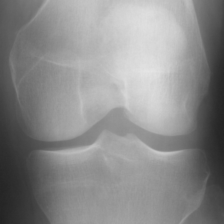

KL 1 | aset_penelitian/dataset/raw/train/1/9000622L.png


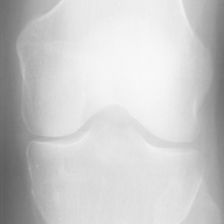

KL 2 | aset_penelitian/dataset/raw/train/2/9000099R.png


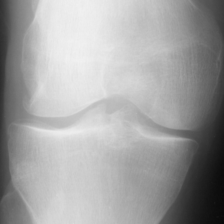

KL 3 | aset_penelitian/dataset/raw/train/3/9000099L.png


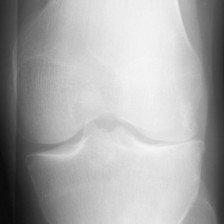

KL 4 | aset_penelitian/dataset/raw/train/4/9025994L.png


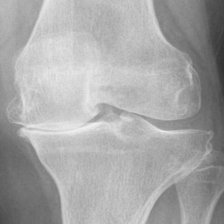

In [107]:
for grade, path in enumerate(contoh):
    print(f'KL {grade} | {path.as_posix()}')
    display(Image(data=path.read_bytes(), format='png'))


## 3. Prapemrosesan citra

Baca citra sebagai grayscale (satu kanal) lalu samakan ukurannya menjadi **224 x 224 piksel**. Hasil ini menjadi masukan yang sama untuk semua skenario. Pada B0, citra berhenti di tahap ini.

KL 0 sebelum: (224, 224), uint8
KL 0 sesudah: (224, 224), uint8


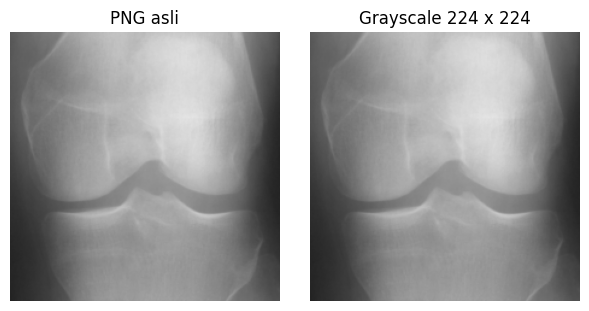

In [108]:
def praproses(path):
    gambar = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gambar is None:
        raise ValueError(f'Gambar gagal dibaca: {path}')
    return cv2.resize(gambar, (224, 224), interpolation=cv2.INTER_LINEAR)


citra_praproses = [praproses(path) for path in contoh]
asli = cv2.imread(str(contoh[0]), cv2.IMREAD_UNCHANGED)
sesudah = citra_praproses[0]

print(f'KL 0 sebelum: {asli.shape}, {asli.dtype}')
print(f'KL 0 sesudah: {sesudah.shape}, {sesudah.dtype}')

fig, axes = plt.subplots(1, 2, figsize=(6, 3), layout='constrained')
tampilan_asli = cv2.cvtColor(asli, cv2.COLOR_BGR2RGB) if asli.ndim == 3 else asli
axes[0].imshow(tampilan_asli, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('PNG asli')
axes[1].imshow(sesudah, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Grayscale 224 x 224')
for ax in axes:
    ax.axis('off')
plt.show()


## 4. Terapkan CLAHE

CLAHE menyesuaikan kontras di 64 tile (grid 8 x 8). Clip limit 1, 2, 3, dan 5 mengatur pembatasan histogram lokal. [OpenCV](https://docs.opencv.org/4.x/d6/db6/classcv_1_1CLAHE.html) | [Ahmed dan Mstafa (2022)](https://doi.org/10.3390/diagnostics12122939)

In [109]:
def terapkan_clahe(gambar, clip_limit):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=grid)
    return clahe.apply(gambar)


## 5. Bandingkan hasilnya

Bandingkan kolom dalam satu baris karena semuanya berasal dari citra yang sama dan memakai skala abu-abu 0-255. Panel menunjukkan perubahan kontras. Kinerja klasifikasi dinilai pada tahap berikutnya. B0 menampilkan hasil prapemrosesan sebelum CLAHE.

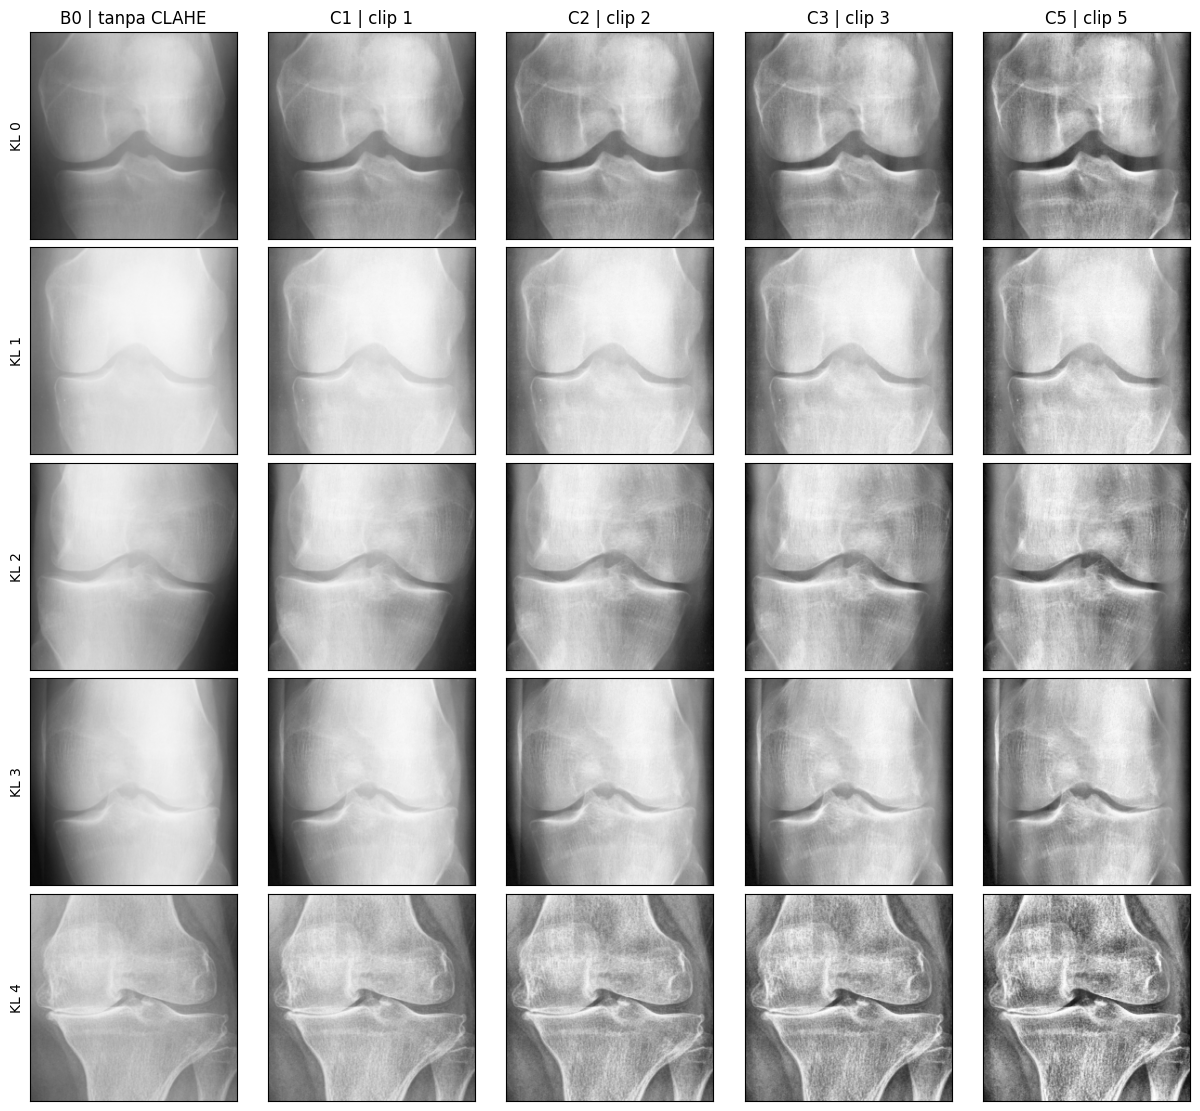

Gambar tersimpan di aset_penelitian\hasil\progres_pertama.png


In [110]:
judul = ['B0 | tanpa CLAHE'] + [f'C{limit} | clip {limit}' for limit in clip_limits]
fig, axes = plt.subplots(len(contoh), len(judul), figsize=(12, 11), layout='constrained')

for grade, baseline in enumerate(citra_praproses):
    versi = [baseline] + [terapkan_clahe(baseline, limit) for limit in clip_limits]
    for col, gambar in enumerate(versi):
        ax = axes[grade, col]
        ax.imshow(gambar, cmap='gray', vmin=0, vmax=255)
        ax.set(xticks=[], yticks=[])
        if grade == 0:
            ax.set_title(judul[col])
    axes[grade, 0].set_ylabel(f'KL {grade}')

hasil.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(hasil, dpi=120)
plt.show()
print(f'Gambar tersimpan di {hasil}')


## 6. Audit dataset dan Pembagian data

Pemeriksaan konflik label, duplikat. Pembagian 70/10/20 untuk latih, uji, validasi untuk semua skenario

## 7. Pelatihan Model

Efficientnet-B0 untuk klasifikasi KL 0-4 dengan skenario 3 seed

## 8. Evaluasi dan Rekap